In [12]:
from graph import create_graph


In [13]:
state_graph=create_graph()
graph_v0=state_graph.compile() #no memory

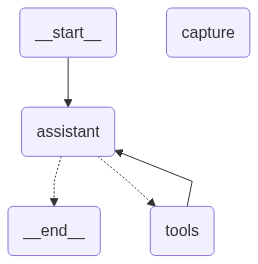

In [14]:
from IPython.display import Image,display

try:
    display(Image(graph_v0.get_graph().draw_mermaid_png()))
except Exception as ex:
    print("render png")

In [9]:
##talk to graph

In [4]:
from langchain_core.messages import HumanMessage

# turn_1=graph_v0.invoke({
#     "messages":[HumanMessage("I need a fix for skin detan")]

# })

turn_1=graph_v0.invoke({
    "messages":[HumanMessage("I need a fix for skin detan.?")]
})

turn_1["messages"][-1].pretty_print()

# turn_2=graph_v0.invoke({
#     "messages":[HumanMessage("which product did you just recommend?")]

# })

# turn_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': "For detanning, I recommend the **Radiance C Vitamin Serum**. It's designed to improve the appearance of dull skin and uneven skin tone, which can help with detanning.\n\nWould you like to know more about this product, or are you also looking for something to prevent tanning in the future?", 'extras': {'signature': 'CrgHAY89a1+u3q49/sopSvHgAHACQYNj0ozinMKn3pSjPk1fXHWIeW13DWvdBWEdS2hV+fNUgFYJPlPvuHptiAbKeG55l/v0Dm/+rUS6q78QrYpg6zFbL9wQYDZJO/3rjbYpz2qCBpp/IsuwLuh7BI5xKmcn4e4B/6G2PGY/Mpa3mQfyZduohALbmfg51+ciotkM77m2K614jPGbCl9K3KU1bfvf7K4UNK7x7oEsN5cxSOadn9iopyMnD6NVp1jr53y1syjurlOYHobxki4FS3MZDiy9/KNrG3bM1NzmMg/nAXwpJxAoJc0poH1N6FteaD37vKx9Rfr15n5DgZTTyBCiMQvljl0Lgay8lfVbBHeqdDff68lMshanwcp6eN9lSwD9bWk7MPzBdh/NfLauiW0ZB94BFmTVPrxDloVcmyVhL5iIo3tLSDsKIF5+fY/QuXSECPPq9//bVuOzrp9EBak5BRm7cFLmH9aXpcfnsicpSLeaxe1z1ugYcf5lAuFBOAZyjfJOek2KxnosaLp+bz4F7YJ2Ti50XE/awth7H9Ni8ZDexK+QKIslfw3lXw

## problem

* we are about to ask a follow up question
* the agent has no idea


In [5]:
turn_2=graph_v0.invoke({
    "messages":[HumanMessage("which product did you just recommend?")]

})

turn_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': "I haven't recommended any product yet. How can I help you today?", 'extras': {'signature': 'CuUBAY89a19+v+EC7rvNdlOOxKUXJ6GJy9DkyDf2ktuMrJ5UdPfY+h/9gGrGmJBR4/ZrDsqWVkhqInFfNMj0syOJ+MZ7dOB8RIAfKKlCMXfqxl3WFlguCc4ZsG5JoN0nqG27Ie6qXiiQ3l04unsfoMBF6peTsAPQ4h52QWlsHaIeaOwVRq+gas9VHS6SiGeOoJBhSsFYFJCUty/fpnnpi3ax7DjW9kCVO5hdVcwv5imE1A6UQQJD6YAHWwdpvi+bA1673qLPN9wTszF4MscCLPgIKuFbkrJlDp2JHPjBQUm3VkGHhNEDCg=='}}]


In [ ]:
print("message at the end of turn_1:", len(turn_1["messages"]))

print("messages at the end of turn_2: ",len(turn_2["messages"]))



message at the end of turn_1: 4
messages at the end of turn_2:  2


In [8]:
from langgraph.checkpoint.memory import InMemorySaver

In [39]:
checkpointers=InMemorySaver()
graph_v1=state_graph.compile(checkpointer=checkpointers)

In [40]:
cfg = {"configurable": {"thread_id": "user-123"}}

In [41]:
turn_1=graph_v1.invoke({
    "messages":[HumanMessage("I need a fix for skin detan.?")]
},cfg)

turn_1["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': "For skin detan, I recommend the **Radiance C Vitamin Serum**. It's designed to improve the appearance of dull skin and uneven skin tone, which can be a result of tanning.\n\nWould you like to know more about this product?", 'extras': {'signature': 'AY89a1+ds+rvRH18oeSCsVoWHUhhR8GapuaGQhq/flv8QRcjmciJ6nghOtbFvYRDaEoeu+vLO2gyHjZF4lMtY4W6KNdx+QMTcBEdK9EoCBQBqI0tjnc5iTIXuaon0ghw+1mWy0jSSrTqm5fgjNEEBJQgac3wuw5x23fotw4YAU5laQa5gFG/tVGetB3qYc7g9f4P8AgSjoRqNsrObAR+GVEI/BEPrBefhn6GyDRIqmHKz9mYWzaqYuH2zKdpX6QdaUjvi7Sk/Ir3hVdQZT608rfas5wwQ2zU1OuCzJHpCXAK2mL71G8xitMqwOw9BLfhtH1S3Oklkvay1/2TzN9QREb6tIjclMM1PcYuFB0ECFGsLnaqSUFIeeQAHA2wu4bLbupsEPljyGkxcn4wASaRSdMNjVf/w8/p+RpFczbheLYLyqrydNRd3r9TlHvT9sxkPVMougChfqpfI4eYVRA1qNd/dDqa7OPNosJ6WpIxUisJNbp3YOVgnh2E1YaZ4nxM8Fjh7s4nrf/Nxrwos1WH0IVpqI9qzTYAwbXTF4hVnHQktUwI7kHlAtoC1M9hv2+0lljpt9bFK5k9IvpKOz8OaSTtV4/9Axo/8A6Y1/Gv/pKMlBhNNnNRFQTfUMm2b+ZYaL

In [43]:
turn_2=graph_v1.invoke({
    "messages":[HumanMessage("which product did you just recommend?")]

},cfg)

turn_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'I recommended the **Radiance C Vitamin Serum**.', 'extras': {'signature': 'AY89a1/u9tiy09j9Jk+V7+jOtNthMxOU/RykGMbvLpEM9rBF64yjS+t2ayzzVloQUYjv+O9D1SC+Lxh0cD/h6C0AGhEUid/Cd0S5J1DlyWS/ONMd08rP4Jf6LTUXPVIEQ50aBkd8HROTUgYYLWZKEuWWuItFR6ORGyc7AwLLoyG5zETivlMgNI6kK6qYKo2BI9K5bXqjQcd26aAmRFB7K3M2XRcLZuo5fObMTOCL65TzKeJ6saGmEbHy9EZW2A2DGr3AnRM0xavCdgcHH3xiHuHITkuA+q+4pOkf2ochQDLg'}}]


In [44]:
print("message at the end of turn_1:", len(turn_1["messages"]))

print("messages at the end of turn_2: ",len(turn_2["messages"]))



message at the end of turn_1: 4
messages at the end of turn_2:  6


In [46]:
snapshot=graph_v1.get_graph(cfg)
snapshot

Graph(nodes={'__start__': Node(id='__start__', name='__start__', data=RunnableCallable(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None), 'assistant': Node(id='assistant', name='assistant', data=assistant(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None), 'tools': Node(id='tools', name='tools', data=tools(tags=None, recurse=True, explode_args=False, func_accepts={'config': ('N/A', <class 'inspect._empty'>), 'runtime': ('N/A', <class 'inspect._empty'>)}, _tools_by_name={'get_product': StructuredTool(name='get_product', description='Get a specific product from the LReal product catalog using its product ID.\n\nArgs:\n    product_id (str): Unique product ID of the product to retrieve.\n        Example: "LREAL-SKIN-001"\n\nReturns:\n    str: The product details in a single pipe-delimited line containing\n    all product attributes:\n\n    product_id | category | product_name | description | price_inr |\n    size | how_to_use | benefit

In [ ]:
def chat(thread_id="new-session"):
    cfg={"configurable":{"thread_id":thread_id}}
    print(f"chatting on thread:{thread_id}")

    while True:
        text=input("you: ")
        if text.strip().lower() in {"exit","quit"," "}:
            print("\n ending")
            break
        out=graph_v1.invoke({"messages": [HumanMessage(text)]},cfg)